<a href="https://colab.research.google.com/github/rifqiiiz/datascience-project/blob/main/01_learning_problem_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 - Learning Problem & Exploratory Data Analysis (EDA) **[L]**

**Judul Proyek:** Prediksi Tingkat Kepadatan Lalu Lintas Perkotaan Menggunakan Algoritma Klasifikasi Machine Learning dan Multilayer Perceptron (PyTorch) Berbasis Data Sensor Jalan Raya  
**Nama / NIM:** Muhammad Rifqi Maulana / 244311018, Vicky Rizkyanto / 244311030

**Program Studi:** D4 Teknologi Rekayasa Perangkat Lunak – Politeknik Negeri Madiun  
**Mata Kuliah:** Data Science (TRPL22406)  
**SDG:** SDG 11 – Kota dan Permukiman yang Berkelanjutan (Target 11.2)

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Memuat dataset Metro Interstate Traffic Volume dari UCI ML Repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00492/Metro_Interstate_Traffic_Volume.csv.gz"
df = pd.read_csv(url, compression="gzip")

print(f"Jumlah baris (rows): {df.shape[0]}")
print(f"Jumlah kolom (columns): {df.shape[1]}")
df.head()

Jumlah baris (rows): 48204
Jumlah kolom (columns): 9


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [7]:
# Membuat label kategorikal tingkat kepadatan lalu lintas berdasarkan kuantil/ambang batas volume kendaraan
# 0: Lancar (< 2.500 kendaraan/jam)
# 1: Padat (2.500 - 4.999 kendaraan/jam)
# 2: Macet (>= 5.000 kendaraan/jam)
def categorize_traffic(volume):
    if volume < 2500:
        return "Lancar"
    elif volume < 5000:
        return "Padat"
    else:
        return "Macet"

df["traffic_density"] = df["traffic_volume"].apply(categorize_traffic)

# Ekstraksi fitur waktu dasar untuk keperluan EDA
df["date_time"] = pd.to_datetime(df["date_time"])
df["hour"] = df["date_time"].dt.hour
df["day_of_week"] = df["date_time"].dt.dayofweek
df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

# Pengecekan kondisi data (Bab 4.3)
print("=== Missing Values ===")
print(df.isnull().sum())

print(f"\n=== Duplicate Rows ===\nJumlah baris duplikat: {df.duplicated().sum()}")

print("\n=== Distribusi Kelas Target ===")
print(df["traffic_density"].value_counts(normalize=True) * 100)

=== Missing Values ===
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
traffic_density            0
hour                       0
day_of_week                0
is_weekend                 0
dtype: int64

=== Duplicate Rows ===
Jumlah baris duplikat: 17

=== Distribusi Kelas Target ===
traffic_density
Padat     40.117003
Lancar    36.324786
Macet     23.558211
Name: proportion, dtype: float64


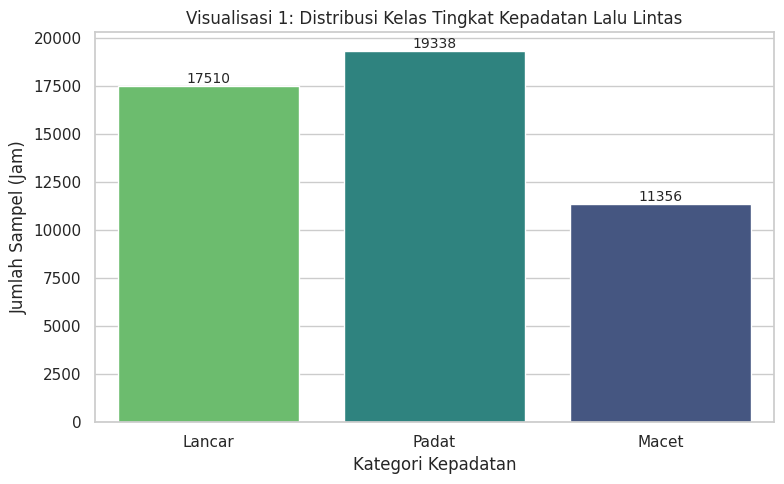

In [8]:
plt.figure(figsize=(8, 5))
order = ["Lancar", "Padat", "Macet"]
ax = sns.countplot(data=df, x="traffic_density", order=order, hue="traffic_density", palette="viridis", legend=False)
plt.title("Visualisasi 1: Distribusi Kelas Tingkat Kepadatan Lalu Lintas")
plt.xlabel("Kategori Kepadatan")
plt.ylabel("Jumlah Sampel (Jam)")

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.show()

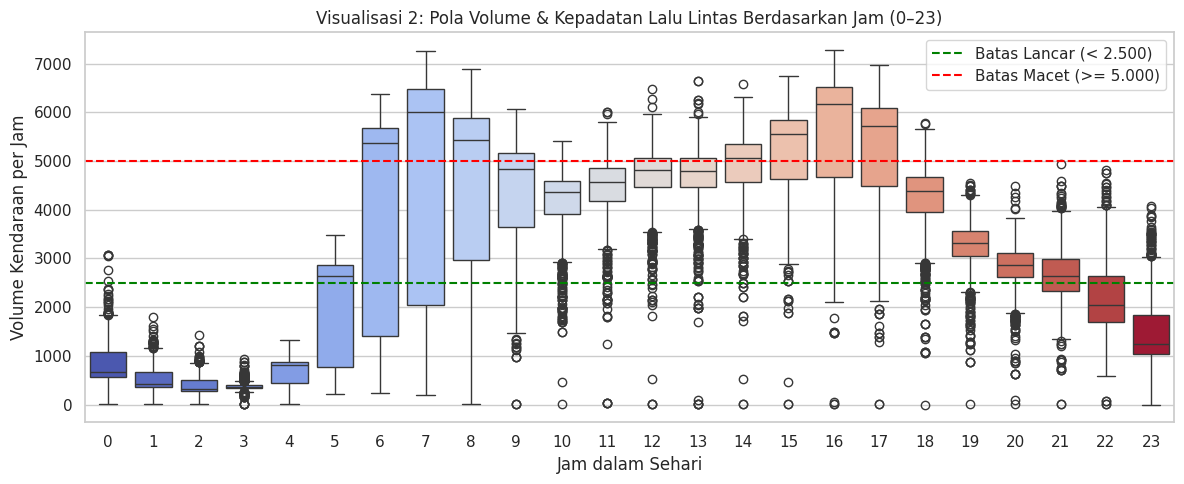

In [9]:
plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="hour", y="traffic_volume", hue="hour", palette="coolwarm", legend=False)
plt.axhline(2500, color="green", linestyle="--", label="Batas Lancar (< 2.500)")
plt.axhline(5000, color="red", linestyle="--", label="Batas Macet (>= 5.000)")
plt.title("Visualisasi 2: Pola Volume & Kepadatan Lalu Lintas Berdasarkan Jam (0–23)")
plt.xlabel("Jam dalam Sehari")
plt.ylabel("Volume Kendaraan per Jam")
plt.legend()
plt.tight_layout()
plt.show()

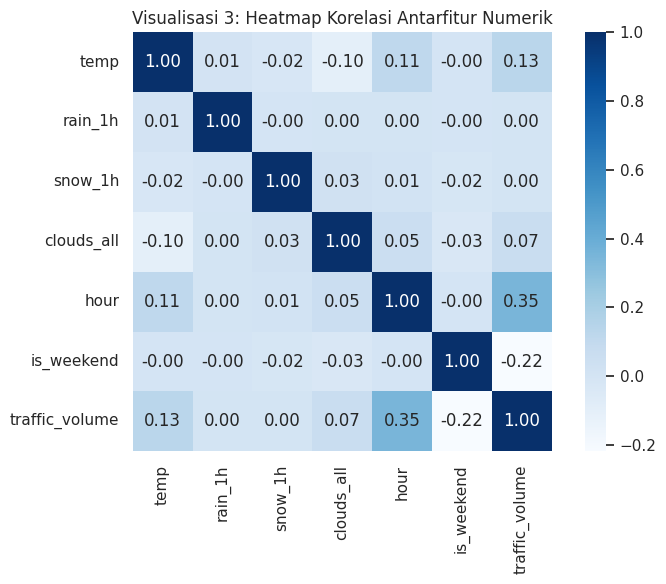

In [10]:
plt.figure(figsize=(8, 6))
num_cols = ["temp", "rain_1h", "snow_1h", "clouds_all", "hour", "is_weekend", "traffic_volume"]
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="Blues", square=True)
plt.title("Visualisasi 3: Heatmap Korelasi Antarfitur Numerik")
plt.tight_layout()
plt.show()